In [1]:
%pip install matplotlib numpy scikit-learn opencv-python-headless kagglehub mlflow

Note: you may need to restart the kernel to use updated packages.


In [2]:
# ==========================================
# 1. IMPORT LIBRARIES
# ==========================================

from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split
import tensorflow as tf
from tensorflow.keras import models
from sklearn.metrics import confusion_matrix, classification_report, accuracy_score, ConfusionMatrixDisplay


2026-10-23 14:25:31.289472: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:467] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1792765531.312324    3572 cuda_dnn.cc:8579] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1792765531.319906    3572 cuda_blas.cc:1407] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
W0000 00:00:1792765531.338254    3572 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1792765531.338282    3572 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1792765531.338284    3572 computation_placer.cc:177] computation placer alr

AttributeError: 'MessageFactory' object has no attribute 'GetPrototype'

AttributeError: 'MessageFactory' object has no attribute 'GetPrototype'

AttributeError: 'MessageFactory' object has no attribute 'GetPrototype'

AttributeError: 'MessageFactory' object has no attribute 'GetPrototype'

AttributeError: 'MessageFactory' object has no attribute 'GetPrototype'

In [3]:
# ==========================================
# 2. DOWNLOAD AND CONFIGURE THE DATASET
# ==========================================


import kagglehub

# Download latest version
path = kagglehub.dataset_download("karapy/neurovision")

print("Path to dataset files:", path)

Path to dataset files: /root/.cache/kagglehub/datasets/karapy/neurovision/versions/1


In [4]:
# DATA = Path('/kaggle/input/datasets/karapy/neurovision/Data/')

In [5]:
DATA = Path("/root/.cache/kagglehub/datasets/karapy/neurovision/versions/1/Data")

In [6]:
# Target image dimensions: 224 pixels high and 224 pixels wide

SIZE = (224, 224)

# Accepted image file extensions

EXTS = {'.jpeg', '.jpg', '.bmp', '.png'}

# Fixed random seed to make data splitting and shuffling reproducible

RANDOM_SEED = 42


# Number of images processed in each batch during training

BATCH = 32


In [7]:
# ==========================================
# 3. IDENTIFY THE IMAGE CLASSES
# ==========================================

# Each subdirectory inside DATA represents an MRI classification category
arr_names = []
for folder in DATA.iterdir():
    arr_names.append(folder.name)

arr_names

['glioma', 'meningioma', 'notumor', 'pituitary']

In [8]:
# ==========================================
# 4. COLLECT IMAGE PATHS AND LABELS
# ==========================================


def load_dataset(data_dir=DATA, arr_names=arr_names):

    # Store file paths instead of loading all image pixels into memory

    imgs_path_str, labels = [], []


    for class_name in arr_names:

        image_path = data_dir / class_name

        for path in image_path.iterdir():

            if path.suffix.lower() not in EXTS:
                continue

            imgs_path_str.append(str(path))
            labels.append(class_name)

    # Return NumPy arrays containing paths and their corresponding labels
    
    return np.array(imgs_path_str), np.array(labels)


In [9]:
# Collect image paths and class labels

imgs_path, labels = load_dataset()


# Check the number of collected paths and labels

print(imgs_path.shape, labels.shape)

# Inspect one image path and its corresponding class

print(imgs_path[0])
print(labels[0])

# Count how many images belong to each class

print(np.unique(labels, return_counts=True))

(7023,) (7023,)
/root/.cache/kagglehub/datasets/karapy/neurovision/versions/1/Data/glioma/Te-glTr_0000.jpg
glioma
(array(['glioma', 'meningioma', 'notumor', 'pituitary'], dtype='<U10'), array([1621, 1645, 2000, 1757]))


In [10]:
# ==========================================
# 5. ENCODE THE CLASS LABELS
# ==========================================


# Neural networks work with numerical targets rather than text labels

le = LabelEncoder()
labels_int = le.fit_transform(labels)

# Display the mapping between integer labels and original class names

print("Class mapping:", dict(enumerate(le.classes_)))
print(len(labels_int))

Class mapping: {0: np.str_('glioma'), 1: np.str_('meningioma'), 2: np.str_('notumor'), 3: np.str_('pituitary')}
7023


## Split data

In [11]:
# ==========================================
# 6. SPLIT THE DATASET
# ==========================================

# Reserve 80% for training and 20% for temporary data

X_train, X_temp, y_train, y_temp = train_test_split( imgs_path, labels_int, 
                                                            test_size=0.2, 
                                                            stratify=labels_int, 
                                                            random_state=RANDOM_SEED )

# Divide the temporary 20% equally:
# 10% for validation and 10% for testing

X_val, X_test, y_val, y_test = train_test_split( X_temp, y_temp, 
                                                        test_size=0.5, 
                                                        stratify=y_temp, 
                                                        random_state=RANDOM_SEED )

# Inspect the sizes of the three datasets

print("Train:", X_train.shape, y_train.shape)
print("Validation:", X_val.shape, y_val.shape)
print("Test:", X_test.shape, y_test.shape)

Train: (5618,) (5618,)
Validation: (702,) (702,)
Test: (703,) (703,)


In [12]:
# ==========================================
# 7. CREATE TF.DATA DATASETS
# ==========================================

# Create TensorFlow datasets from image paths and integer labels

train_ds = tf.data.Dataset.from_tensor_slices((X_train, y_train))

val_ds = tf.data.Dataset.from_tensor_slices((X_val, y_val))

test_ds = tf.data.Dataset.from_tensor_slices((X_test, y_test))


I0000 00:00:1792765536.852520    3572 gpu_device.cc:2019] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 10313 MB memory:  -> device: 0, name: NVIDIA GeForce RTX 3060, pci bus id: 0000:03:00.0, compute capability: 8.6


In [13]:
# ==========================================
# 8. LOAD AND PREPROCESS IMAGES
# ==========================================


def load_img(path, label):
    img = tf.io.read_file(path)
 
    img = tf.io.decode_image( img, 
                             channels=3, 
                             expand_animations=False )

    # resize the images
    img = tf.image.resize(img, SIZE)

    # normalize pixel values
    img = tf.keras.applications.resnet50.preprocess_input(img)

    return img, label

In [14]:
# ==========================================
# 9. BUILD THE INPUT PIPELINE
# ==========================================

# Training pipeline: map() -> shuffle() -> batch() -> prefetch()

train_ds = train_ds.map(load_img).shuffle(len(X_train), seed=RANDOM_SEED).batch(BATCH).prefetch(tf.data.AUTOTUNE)

val_ds = val_ds.map(load_img).batch(BATCH).prefetch(tf.data.AUTOTUNE)

test_ds = test_ds.map(load_img).batch(BATCH).prefetch(tf.data.AUTOTUNE)


# **ResNet50**

In [15]:
# ==========================================
# 10. LOAD THE PRETRAINED ResNet50 MODEL
# ==========================================

base_model = tf.keras.applications.ResNet50(weights='imagenet',
                         include_top=False,
                         input_shape=(224, 224, 3))

base_model.trainable = False

In [ ]:
# ==========================================
# 11. DEFINE TRAINING CALLBACKS
# ==========================================

early_stop = tf.keras.callbacks.EarlyStopping( monitor="val_loss", 
                                              patience=3, 
                                              restore_best_weights=True )

checkpoint = tf.keras.callbacks.ModelCheckpoint('resnet_mri.keras', save_best_only=True)


In [17]:
# ==========================================
# 12. BUILD THE CLASSIFICATION MODEL
# ==========================================


resNet_model = models.Sequential()

resNet_model.add(base_model)

# augmentation
resNet_model.add(tf.keras.layers.RandomContrast(factor=0.10))
resNet_model.add(tf.keras.layers.RandomFlip(mode='horizontal'))
resNet_model.add(tf.keras.layers.RandomRotation(factor=0.10))


resNet_model.add(tf.keras.layers.GlobalAveragePooling2D())
resNet_model.add(tf.keras.layers.Dense(128, activation='relu'))
resNet_model.add(tf.keras.layers.Dropout(0.1))
resNet_model.add(tf.keras.layers.Dense(4, activation='softmax'))

resNet_model.summary()


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ resnet50 (Functional)           │ (None, 7, 7, 2048)     │    23,587,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_contrast                 │ (None, 7, 7, 2048)     │             0 │
│ (RandomContrast)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_flip (RandomFlip)        │ (None, 7, 7, 2048)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_rotation                 │ (None, 7, 7, 2048)     │             0 │
│ (RandomRotation)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 2048)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       262,272 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 4)              │           516 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 23,850,500 (90.98 MB)

 Trainable params: 262,788 (1.00 MB)

 Non-trainable params: 23,587,712 (89.98 MB)

In [18]:
# ==========================================
# 13. COMPILE THE MODEL
# ==========================================

resNet_model.compile(optimizer='adam', 
                     loss='sparse_categorical_crossentropy', 
                     metrics=['accuracy'])

In [19]:
# ==========================================
# 14. TRAIN THE MODEL
# ==========================================


resNet_model_history = resNet_model.fit( train_ds, 
                                  epochs=15, 
                                  validation_data=val_ds, 
                                  verbose=2, 
                                  callbacks=[early_stop, checkpoint] )

Epoch 1/15


I0000 00:00:1792765557.620757    3764 cuda_dnn.cc:529] Loaded cuDNN version 90300


176/176 - 38s - 216ms/step - accuracy: 0.8432 - loss: 0.4147 - val_accuracy: 0.8775 - val_loss: 0.3096
Epoch 2/15
176/176 - 22s - 124ms/step - accuracy: 0.9151 - loss: 0.2255 - val_accuracy: 0.9031 - val_loss: 0.2307
Epoch 3/15
176/176 - 21s - 119ms/step - accuracy: 0.9402 - loss: 0.1642 - val_accuracy: 0.9046 - val_loss: 0.2457
Epoch 4/15
176/176 - 22s - 125ms/step - accuracy: 0.9462 - loss: 0.1391 - val_accuracy: 0.9117 - val_loss: 0.2130
Epoch 5/15
176/176 - 22s - 123ms/step - accuracy: 0.9482 - loss: 0.1277 - val_accuracy: 0.9274 - val_loss: 0.1708
Epoch 6/15
176/176 - 21s - 117ms/step - accuracy: 0.9632 - loss: 0.0993 - val_accuracy: 0.9231 - val_loss: 0.2313
Epoch 7/15
176/176 - 20s - 115ms/step - accuracy: 0.9655 - loss: 0.0951 - val_accuracy: 0.9188 - val_loss: 0.2119
Epoch 8/15
176/176 - 22s - 124ms/step - accuracy: 0.9765 - loss: 0.0698 - val_accuracy: 0.9530 - val_loss: 0.1255
Epoch 9/15
176/176 - 21s - 117ms/step - accuracy: 0.9770 - loss: 0.0670 - val_accuracy: 0.9359 - va

In [ ]:
# ==========================================
# 15. MAKE PREDICTIONS ON THE TEST DATASET
# ==========================================

resNet_model_pred = resNet_model.predict(test_ds)

20/22 ━━━━━━━━━━━━━━━━━━━━ 0s 51ms/step

2026-10-22 15:44:21.020808: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_1681', 4 bytes spill stores, 4 bytes spill loads

2026-10-22 15:44:21.465401: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_1681', 220 bytes spill stores, 220 bytes spill loads

2026-10-22 15:44:21.549403: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_1681', 8 bytes spill stores, 8 bytes spill loads

2026-10-22 15:44:22.272436: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_1681', 4384 bytes spill stores, 4228 bytes spill loads

2026-10-22 15:44:22.491839: I external

22/22 ━━━━━━━━━━━━━━━━━━━━ 15s 488ms/step


## **Fine-tuning** 

In [23]:
checkpoint = tf.keras.callbacks.ModelCheckpoint('fine_tunnung_resNet_model_mri.keras', save_best_only=True)

In [ ]:
# ==========================================
# 16. PREPARE THE MODEL FOR FINE-TUNING
# ==========================================

base_model.trainable = True

# Freeze all layers except the last 30
for layer in base_model.layers[:-30]:
    layer.trainable = False


# ==========================================
# 17. KEEP BATCH NORMALIZATION LAYERS FROZEN
# ==========================================


for layer in base_model.layers:
    if isinstance(layer, tf.keras.layers.BatchNormalization):
        layer.trainable = False

# ==========================================
# 18. RECOMPILE THE MODEL FOR FINE-TUNING
# ==========================================

resNet_model.compile( optimizer=tf.keras.optimizers.Adam(learning_rate=1e-5), 
                     loss='sparse_categorical_crossentropy', 
                     metrics=['accuracy'])


# ==========================================
# 19. CONTINUE TRAINING WITH FINE-TUNING
# ==========================================

resNet_model_history_finetune = resNet_model.fit( train_ds, 
                                           epochs=10, 
                                           validation_data=val_ds, 
                                           callbacks=[early_stop, checkpoint], 
                                           verbose=2 )

Epoch 1/10


I0000 00:00:1792756256.692387     143 cuda_solvers.cc:175] Creating GpuSolver handles for stream 0x63b0f10


176/176 - 56s - 317ms/step - accuracy: 0.9491 - loss: 0.1345 - val_accuracy: 0.9473 - val_loss: 0.1333
Epoch 2/10
176/176 - 43s - 244ms/step - accuracy: 0.9694 - loss: 0.0836 - val_accuracy: 0.9501 - val_loss: 0.1141
Epoch 3/10
176/176 - 43s - 244ms/step - accuracy: 0.9801 - loss: 0.0602 - val_accuracy: 0.9630 - val_loss: 0.1001
Epoch 4/10
176/176 - 43s - 243ms/step - accuracy: 0.9874 - loss: 0.0390 - val_accuracy: 0.9672 - val_loss: 0.0978
Epoch 5/10
176/176 - 42s - 237ms/step - accuracy: 0.9893 - loss: 0.0315 - val_accuracy: 0.9715 - val_loss: 0.0983
Epoch 6/10
176/176 - 41s - 236ms/step - accuracy: 0.9932 - loss: 0.0213 - val_accuracy: 0.9701 - val_loss: 0.1224
Epoch 7/10
176/176 - 42s - 236ms/step - accuracy: 0.9957 - loss: 0.0156 - val_accuracy: 0.9615 - val_loss: 0.1181


## PLots

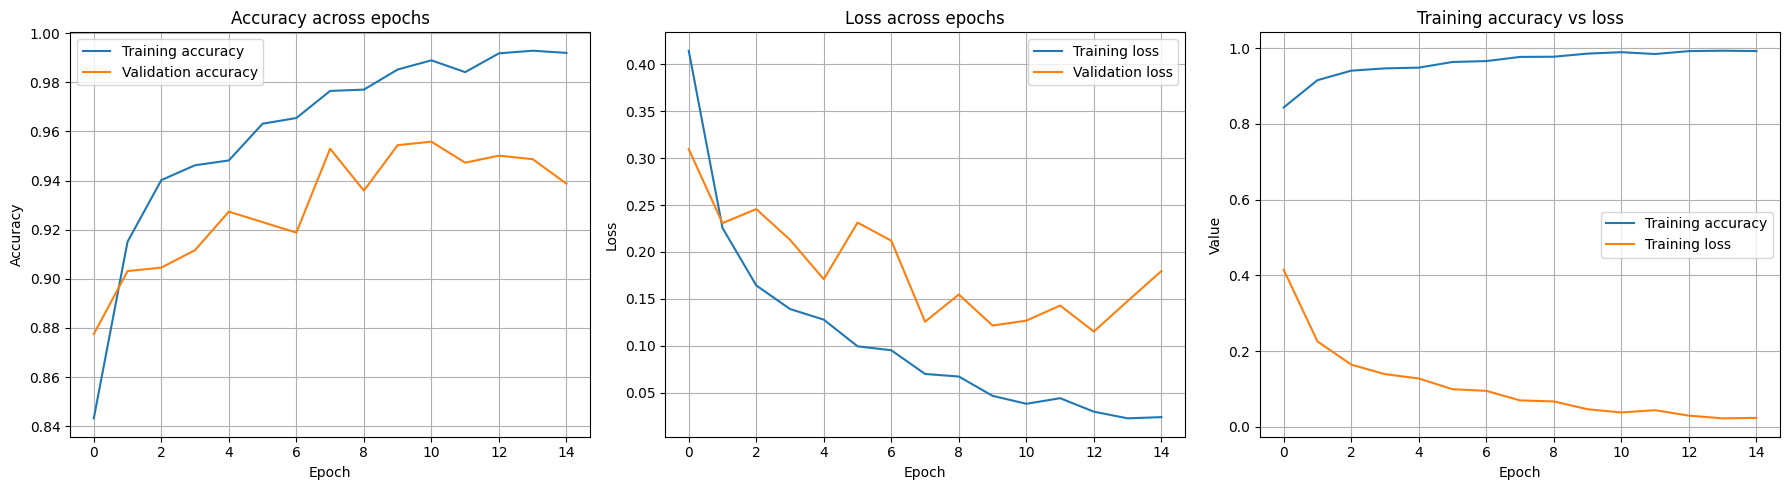

In [ ]:
# ==========================================
# 20. PLOTS
# ==========================================


# Transfer Learning with ResNet plots 


fig, axes = plt.subplots(1, 2, figsize=(10, 5))

# 1. Accuracy across epochs
axes[0].plot(resNet_model_history.history['accuracy'], label='Training accuracy')
axes[0].plot(resNet_model_history.history['val_accuracy'], label='Validation accuracy')
axes[0].set_title('Accuracy across epochs')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Accuracy')
axes[0].legend()
axes[0].grid(True)

# 2. Loss across epochs
axes[1].plot(resNet_model_history.history['loss'], label='Training loss')
axes[1].plot(resNet_model_history.history['val_loss'], label='Validation loss')
axes[1].set_title('Loss across epochs')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Loss')
axes[1].legend()
axes[1].grid(True)


# Adjust spacing to prevent overlapping titles and labels
plt.tight_layout()
plt.show()

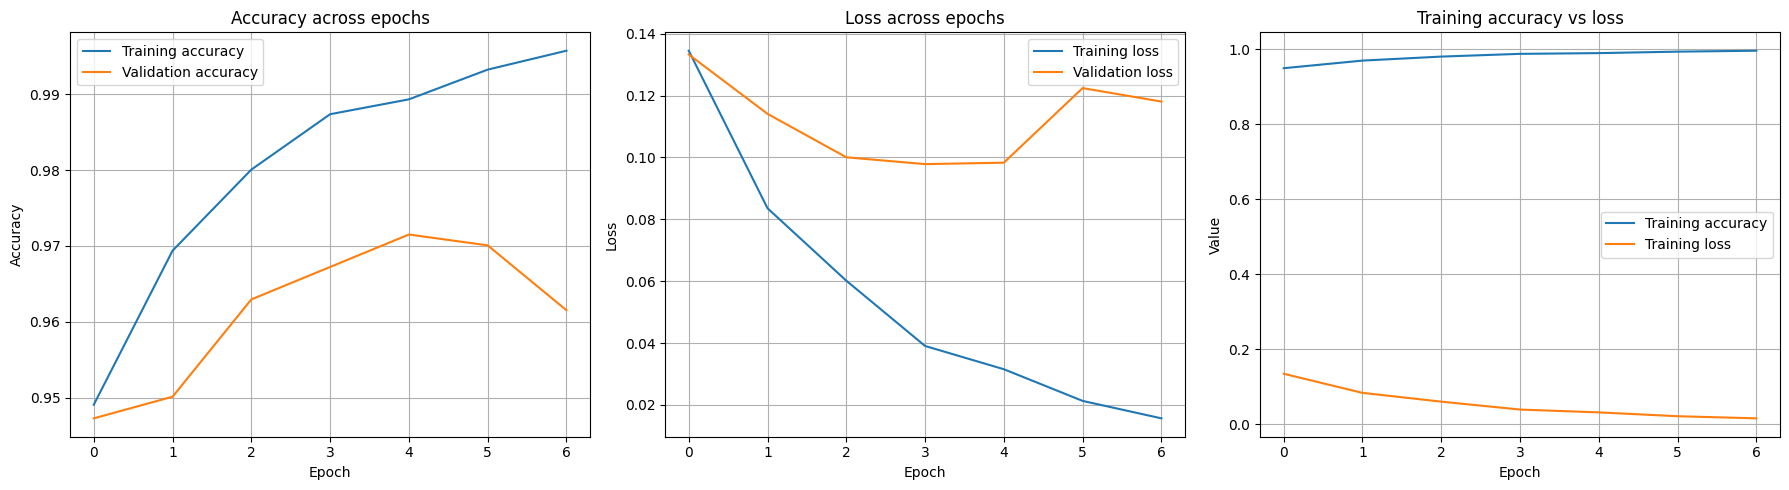

In [ ]:
# fine-tunning with ResNet plots

fig, axes = plt.subplots(1, 2, figsize=(10, 5))

axes[0].plot(resNet_model_history_finetune.history['accuracy'], label='Training accuracy')
axes[0].plot(resNet_model_history_finetune.history['val_accuracy'], label='Validation accuracy')
axes[0].set_title('Accuracy across epochs')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Accuracy')
axes[0].legend()
axes[0].grid(True)

axes[1].plot(resNet_model_history_finetune.history['loss'], label='Training loss')
axes[1].plot(resNet_model_history_finetune.history['val_loss'], label='Validation loss')
axes[1].set_title('Loss across epochs')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Loss')
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.show()